In [1]:
import torch
import transformers
import datasets
import accelerate
import huggingface_hub

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

print("\nGPU Available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
Transformers: 4.48.3
Datasets: 3.2.0
Accelerate: 1.2.1
Hugging Face Hub: 0.36.2

GPU Available: True


In [2]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)

print("All required Transformers classes imported successfully!")

All required Transformers classes imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

Saving Climate-Stance-Detection-for-Indic-Languages-main.zip to Climate-Stance-Detection-for-Indic-Languages-main.zip


In [4]:
import zipfile
import os

zip_path = "/content/Climate-Stance-Detection-for-Indic-Languages-main.zip"
extract_path = "/content/climate_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

# Display extracted files
for root, dirs, files_list in os.walk(extract_path):
    for file in files_list:
        print(os.path.join(root, file))

Dataset extracted successfully!
/content/climate_dataset/Climate-Stance-Detection-for-Indic-Languages-main/README.md
/content/climate_dataset/Climate-Stance-Detection-for-Indic-Languages-main/dataset/final_train.csv
/content/climate_dataset/Climate-Stance-Detection-for-Indic-Languages-main/dataset/final_multilingual_climate_stance_dataset.csv
/content/climate_dataset/Climate-Stance-Detection-for-Indic-Languages-main/dataset/README.md
/content/climate_dataset/Climate-Stance-Detection-for-Indic-Languages-main/dataset/final_validation.csv


In [5]:
import pandas as pd
import os

# Dataset folder path
dataset_path = "/content/climate_dataset/Climate-Stance-Detection-for-Indic-Languages-main/dataset"

# Load CSV files
train_df = pd.read_csv(os.path.join(dataset_path, "final_train.csv"))
val_df = pd.read_csv(os.path.join(dataset_path, "final_validation.csv"))
full_df = pd.read_csv(os.path.join(dataset_path, "final_multilingual_climate_stance_dataset.csv"))

# Display dataset shapes
print("TRAINING DATASET:", train_df.shape)
print("VALIDATION DATASET:", val_df.shape)
print("FULL MULTILINGUAL DATASET:", full_df.shape)

# Display columns
print("\nColumns:", train_df.columns.tolist())

# Display first five training records
print("\nFirst 5 training records:")
display(train_df.head())

# Check language distribution
print("\nLanguage distribution:")
print(train_df["language"].value_counts())

# Check label distribution
print("\nLabel distribution:")
print(train_df["label"].value_counts(dropna=False))

TRAINING DATASET: (4836, 7)
VALIDATION DATASET: (1209, 7)
FULL MULTILINGUAL DATASET: (6045, 7)

Columns: ['text', 'label', 'language', 'split', 'source', 'translation_status', 'original_id']

First 5 training records:


,text,label,language,split,source,translation_status,original_id
0,Fracking wells leak massive quantities of meth...,NaN,English,train,combined_dataset.csv,original,train_0
1,Brilliant talk from @GeorgeMonbiot #Dali Lama ...,NaN,English,train,combined_dataset.csv,original,train_1
2,Working with artists & culture is key to weave...,NaN,English,train,combined_dataset.csv,original,train_2
3,A warning sign that some scientists worry coul...,Favour,English,train,combined_dataset.csv,original,train_3
4,The Arctic had the power to put the United Sta...,NaN,English,train,combined_dataset.csv,original,train_4



Language distribution:
language
English    1612
Hindi      1612
Bengali    1612
Name: count, dtype: int64

Label distribution:
label
NaN        2118
Favour     2043
Against     675
Name: count, dtype: int64


In [6]:
# Replace missing labels with None
train_df["label"] = train_df["label"].fillna("None")
val_df["label"] = val_df["label"].fillna("None")

# Remove extra spaces
train_df["label"] = train_df["label"].str.strip()
val_df["label"] = val_df["label"].str.strip()

# Clean text
train_df["text"] = train_df["text"].fillna("").astype(str).str.strip()
val_df["text"] = val_df["text"].fillna("").astype(str).str.strip()

# Remove rows with empty text
train_df = train_df[train_df["text"] != ""].copy()
val_df = val_df[val_df["text"] != ""].copy()

# Check label distribution
print("TRAINING LABEL DISTRIBUTION:")
print(train_df["label"].value_counts())

print("\nVALIDATION LABEL DISTRIBUTION:")
print(val_df["label"].value_counts())

# Check language-wise label distribution
print("\nTRAINING LANGUAGE-WISE LABEL DISTRIBUTION:")
display(pd.crosstab(train_df["language"], train_df["label"]))

print("\nVALIDATION LANGUAGE-WISE LABEL DISTRIBUTION:")
display(pd.crosstab(val_df["language"], val_df["label"]))

# Check for unexpected labels
print("\nUnique labels:", train_df["label"].unique())

TRAINING LABEL DISTRIBUTION:
label
None       2118
Favour     2043
Against     675
Name: count, dtype: int64

VALIDATION LABEL DISTRIBUTION:
label
None       528
Favour     513
Against    168
Name: count, dtype: int64

TRAINING LANGUAGE-WISE LABEL DISTRIBUTION:


label,Against,Favour,None
language,,,
Bengali,225,681,706
English,225,681,706
Hindi,225,681,706



VALIDATION LANGUAGE-WISE LABEL DISTRIBUTION:


label,Against,Favour,None
language,,,
Bengali,56,171,176
English,56,171,176
Hindi,56,171,176



Unique labels: ['None' 'Favour' 'Against']


In [7]:
# Define label mapping
label2id = {
    "Favour": 0,
    "Against": 1,
    "None": 2
}

id2label = {
    0: "Favour",
    1: "Against",
    2: "None"
}

# Convert text labels into numerical labels
train_df["label_id"] = train_df["label"].map(label2id)
val_df["label_id"] = val_df["label"].map(label2id)

# Verify encoding
print("Training dataset:")
display(train_df[["text", "label", "label_id", "language"]].head(10))

print("\nValidation dataset:")
display(val_df[["text", "label", "label_id", "language"]].head(10))

# Check for missing numerical labels
print("\nMissing training labels:", train_df["label_id"].isna().sum())
print("Missing validation labels:", val_df["label_id"].isna().sum())

Training dataset:


,text,label,label_id,language
0,Fracking wells leak massive quantities of meth...,None,2,English
1,Brilliant talk from @GeorgeMonbiot #Dali Lama ...,None,2,English
2,Working with artists & culture is key to weave...,None,2,English
3,A warning sign that some scientists worry coul...,Favour,0,English
4,The Arctic had the power to put the United Sta...,None,2,English
5,The researchers suspect that the glacial melti...,None,2,English
6,The pace is most consistent with the slowing o...,None,2,English
7,People in the United States the United States ...,Favour,0,English
8,"Exxon, and perhaps the fossil fuel industry mo...",None,2,English
9,@noel_kck @TomSteyer @BillNye @POTUS Further p...,None,2,English



Validation dataset:


,text,label,label_id,language
0,We have to get off of carbon.,Favour,0,English
1,By the end of the century the chance of Sandy-...,None,2,English
2,The world is on the brink of the “ largest bub...,None,2,English
3,To turn a blind eye on how sea-level rise and ...,Favour,0,English
4,Accurate data would be needed if a new interna...,None,2,English
5,#Mission:#Climate @ home > Wash laundry in col...,Favour,0,English
6,Scientists agree that future storms will be sl...,None,2,English
7,It is not feasible to wait for a global agreem...,None,2,English
8,Human-made climate change is a real and urgent...,Favour,0,English
9,Global warming has been behind every catastrop...,Favour,0,English



Missing training labels: 0
Missing validation labels: 0


In [9]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "ai4bharat/IndicBERTv2-MLM-only"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("IndicBERT v2 tokenizer loaded successfully!")
print("Vocabulary size:", tokenizer.vocab_size)

# Load classification model with 3 output classes
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("\nIndicBERT v2 classification model loaded successfully!")
print("Number of labels:", model.config.num_labels)

# Test tokenization
sample_text = "Climate change is a serious concern."

tokens = tokenizer(
    sample_text,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("\nInput IDs shape:", tokens["input_ids"].shape)
print("Attention Mask shape:", tokens["attention_mask"].shape)

tokenizer_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.75M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

IndicBERT v2 tokenizer loaded successfully!
Vocabulary size: 250000


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.12G [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-only and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



IndicBERT v2 classification model loaded successfully!
Number of labels: 3

Input IDs shape: torch.Size([1, 128])
Attention Mask shape: torch.Size([1, 128])


In [10]:
from datasets import Dataset

# Convert Pandas DataFrames into Hugging Face datasets
train_dataset = Dataset.from_pandas(
    train_df[["text", "label_id"]].rename(
        columns={"label_id": "labels"}
    ),
    preserve_index=False
)

val_dataset = Dataset.from_pandas(
    val_df[["text", "label_id"]].rename(
        columns={"label_id": "labels"}
    ),
    preserve_index=False
)

# Define tokenization function
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

# Tokenize training dataset
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

# Tokenize validation dataset
val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

# Remove original text column
train_dataset = train_dataset.remove_columns(["text"])
val_dataset = val_dataset.remove_columns(["text"])

# Display results
print("Training dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))

print("\nDataset features:")
print(train_dataset.features)

print("\nFirst tokenized training example:")
print(train_dataset[0])

Map:   0%|          | 0/4836 [00:00<?, ? examples/s]

Map:   0%|          | 0/1209 [00:00<?, ? examples/s]

Training dataset size: 4836
Validation dataset size: 1209

Dataset features:
{'labels': Value(dtype='int64', id=None), 'input_ids': Sequence(feature=Value(dtype='int32', id=None), length=-1, id=None), 'token_type_ids': Sequence(feature=Value(dtype='int8', id=None), length=-1, id=None), 'attention_mask': Sequence(feature=Value(dtype='int8', id=None), length=-1, id=None)}

First tokenized training example:
{'labels': 2, 'input_ids': [1, 129329, 17530, 15474, 89777, 63307, 31771, 85110, 15472, 209256, 27966, 59, 16199, 15503, 181310, 60, 19950, 19694, 16500, 155324, 16920, 52639, 94809, 15641, 67213, 115540, 32939, 16273, 112, 54047, 60, 16270, 60824, 61, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

In [11]:
import numpy as np
import torch
from sklearn.utils.class_weight import compute_class_weight

# Get numerical labels from training data
y_train = train_df["label_id"].values

# Define classes
classes = np.array([0, 1, 2])

# Calculate balanced class weights
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

# Convert weights into PyTorch tensor
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

# Display class weights
print("Class Mapping:")
print(id2label)

print("\nClass Weights:")
for class_id, weight in enumerate(class_weights):
    print(f"{id2label[class_id]}: {weight.item():.4f}")

print("\nClass weights tensor:", class_weights)

Class Mapping:
{0: 'Favour', 1: 'Against', 2: 'None'}

Class Weights:
Favour: 0.7890
Against: 2.3881
None: 0.7611

Class weights tensor: tensor([0.7890, 2.3881, 0.7611])


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    balanced_accuracy_score,
    matthews_corrcoef
)
import numpy as np

def compute_metrics(eval_pred):

    # Get predictions and actual labels
    logits, labels = eval_pred

    # Convert model outputs into predicted classes
    predictions = np.argmax(logits, axis=-1)

    # Calculate accuracy
    accuracy = accuracy_score(labels, predictions)

    # Calculate macro precision, recall and F1
    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    # Calculate weighted F1
    f1_weighted = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )[2]

    # Calculate micro F1
    f1_micro = precision_recall_fscore_support(
        labels,
        predictions,
        average="micro",
        zero_division=0
    )[2]

    # Calculate balanced accuracy
    balanced_acc = balanced_accuracy_score(
        labels,
        predictions
    )

    # Calculate MCC
    mcc = matthews_corrcoef(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "macro_f1": f1_macro,
        "weighted_f1": f1_weighted,
        "micro_f1": f1_micro,
        "balanced_accuracy": balanced_acc,
        "mcc": mcc
    }

print("Evaluation metrics defined successfully!")
print("Primary evaluation metric: Macro F1-score")

Evaluation metrics defined successfully!
Primary evaluation metric: Macro F1-score


In [13]:
import torch
import torch.nn as nn
from transformers import Trainer

class WeightedTrainer(Trainer):

    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):

        # Extract actual labels
        labels = inputs.pop("labels")

        # Get model predictions
        outputs = model(**inputs)
        logits = outputs.logits

        # Move class weights to the same device as the model
        weights = self.class_weights.to(logits.device)

        # Calculate weighted cross-entropy loss
        loss_function = nn.CrossEntropyLoss(
            weight=weights
        )

        loss = loss_function(
            logits.view(-1, model.config.num_labels),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss


print("Weighted Trainer defined successfully!")

Weighted Trainer defined successfully!


In [14]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="/content/indicbert_v2_results",

    num_train_epochs=4,

    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,

    gradient_accumulation_steps=2,

    weight_decay=0.01,
    warmup_ratio=0.1,

    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    fp16=torch.cuda.is_available(),

    save_total_limit=2,
    report_to="none",

    seed=42
)

print("Training configuration created successfully!")
print("GPU available:", torch.cuda.is_available())
print("Epochs:", training_args.num_train_epochs)
print("Learning rate:", training_args.learning_rate)

Training configuration created successfully!
GPU available: True
Epochs: 4
Learning rate: 2e-05


In [15]:
trainer = WeightedTrainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    compute_metrics=compute_metrics,

    class_weights=class_weights,

    tokenizer=tokenizer
)

print("IndicBERT v2 Trainer initialized successfully!")
print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Model:", MODEL_NAME)

/tmp/ipykernel_2296/1469869755.py:8: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `WeightedTrainer.__init__`. Use `processing_class` instead.
  super().__init__(*args, **kwargs)


IndicBERT v2 Trainer initialized successfully!
Training examples: 4836
Validation examples: 1209
Model: ai4bharat/IndicBERTv2-MLM-only


In [16]:
train_result = trainer.train()

print("\nIndicBERT v2 training completed successfully!")

print("\nTraining Results:")
print(train_result.metrics)

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,Macro F1,Weighted F1,Micro F1,Balanced Accuracy,Mcc
1,0.876400,0.665132,0.737800,0.706235,0.742655,0.713253,0.740734,0.737800,0.742655,0.589681
2,0.432400,0.787937,0.774194,0.765738,0.719173,0.736265,0.770608,0.774194,0.719173,0.624084
3,0.110900,1.144508,0.763441,0.746923,0.714840,0.727741,0.760921,0.763441,0.714840,0.607277



IndicBERT v2 training completed successfully!

Training Results:
{'train_runtime': 543.5329, 'train_samples_per_second': 35.589, 'train_steps_per_second': 2.222, 'total_flos': 1268996013702144.0, 'train_loss': 0.407661093781326, 'epoch': 3.9884297520661156}


In [17]:
# Evaluate the best saved model
final_metrics = trainer.evaluate()

print("\n========== INDICBERT V2 FINAL RESULTS ==========")

for metric, value in final_metrics.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")


========== INDICBERT V2 FINAL RESULTS ==========
eval_loss: 0.9872
eval_accuracy: 0.7717
eval_precision_macro: 0.7469
eval_recall_macro: 0.7348
eval_macro_f1: 0.7402
eval_weighted_f1: 0.7705
eval_micro_f1: 0.7717
eval_balanced_accuracy: 0.7348
eval_mcc: 0.6241
eval_runtime: 6.3318
eval_samples_per_second: 190.9420
eval_steps_per_second: 24.0060
epoch: 3.9884


CLASSIFICATION REPORT:


,precision,recall,f1-score,support
Favour,0.784133,0.828460,0.805687,513.000000
Against,0.666667,0.607143,0.635514,168.000000
None,0.789883,0.768939,0.779271,528.000000
accuracy,0.771712,0.771712,0.771712,0.771712
macro avg,0.746894,0.734847,0.740157,1209.000000
weighted avg,0.770321,0.771712,0.770504,1209.000000


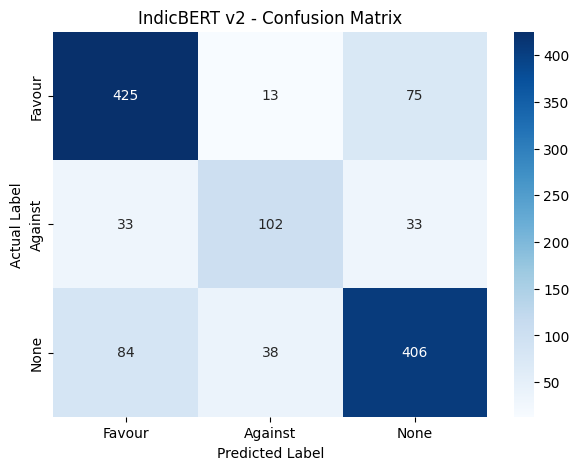

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# Generate predictions on validation dataset
predictions_output = trainer.predict(val_dataset)

predictions = np.argmax(
    predictions_output.predictions,
    axis=1
)

actual_labels = predictions_output.label_ids

# Classification report
report = classification_report(
    actual_labels,
    predictions,
    labels=[0, 1, 2],
    target_names=["Favour", "Against", "None"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("CLASSIFICATION REPORT:")
display(report_df)

# Confusion matrix
cm = confusion_matrix(
    actual_labels,
    predictions,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Favour", "Against", "None"],
    yticklabels=["Favour", "Against", "None"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("IndicBERT v2 - Confusion Matrix")

plt.show()

In [19]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd

language_results = []

# Get validation languages
languages = val_df["language"].values

for language in sorted(val_df["language"].unique()):

    # Select examples belonging to this language
    mask = languages == language

    y_true = actual_labels[mask]
    y_pred = predictions[mask]

    # Calculate metrics
    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    language_results.append({
        "Language": language,
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1
    })

language_df = pd.DataFrame(language_results)

print("INDICBERT V2 LANGUAGE-WISE PERFORMANCE:")
display(language_df.round(4))

INDICBERT V2 LANGUAGE-WISE PERFORMANCE:


,Language,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Bengali,0.7543,0.7319,0.7173,0.7237
1,English,0.7841,0.7701,0.7646,0.7669
2,Hindi,0.7767,0.7370,0.7226,0.7287
